In [1]:
##############
## INITIATE ##
##############

## Imports
import os
import numpy as np
import pandas as pd
from sklearn.metrics import pairwise_distances
from scipy.cluster.hierarchy import linkage, fcluster
import matplotlib.pyplot as plt
import seaborn as sns
from PIL import Image
import cv2

## Figure parameters
plt.rcParams['figure.dpi'] = 300
figsize = (14,5)
custom_params = {'axes.spines.right': False, 
                 'axes.spines.top': False, 
                 'axes.facecolor':'whitesmoke'
                }
sns.set_theme(style="ticks", rc=custom_params)

#
###

In [2]:
###########################
## SCRIPT CONFIGURATIONS ##
###########################

## Note: load embeddings after formatting?

## Define paths
pti = '/Volumes/Elements/BDI/projects/GSG/outputs/o3_mil/icgc-c/model_vit_icgcc_raw_FTL_0/'
embeddings_path = pti + 'encoder/obj_embeddings.npy'
identifiers_path = pti + 'preprocessed/obj_filenames.npy'
dataset_path = '/Volumes/Elements/BDI/projects/GSG/outputs/o1_extracted_glands/icgc-c/'

#
###

In [3]:
######################
## LOAD EMBEDDINGS  ##
######################

## Load the embeddings from the .npy file
embeddings = np.load(embeddings_path, allow_pickle=True)

## Load identifiers
identifiers = np.load(identifiers_path, allow_pickle=True)
# image_filenames = identifiers_df['filename'].tolist()

## Format to np.array
embeddings = np.array([__ for _ in embeddings for __ in _])
image_filenames = np.array([__ for _ in identifiers for __ in _])

## Check the shape of the loaded embeddings and identifiers
print(f'Loaded embeddings shape: {embeddings.shape}')
print(f'Loaded identifiers shape: {image_filenames.shape}')

#
###

Loaded embeddings shape: (66497, 512)
Loaded identifiers shape: (66497,)


In [4]:
#################
## LOAD SCORES ##
#################

PT_SCORES = "/Volumes/Elements/BDI/projects/GSG/outputs/o3_mil/icgc-c/model_vit_icgcc_raw_FTL_0/aggregator_pawmil_1000/singletask-relapse/predictions/"
scores_mid = np.load(PT_SCORES + "obj_paw_scores_mid.npy")
scores_hig = np.load(PT_SCORES + "obj_paw_scores_hig.npy")
scores_low = np.load(PT_SCORES + "obj_paw_scores_low.npy")
print(scores_mid.shape)

#
###

(66497, 1)


In [5]:
###################
## FORMAT SCORES ##
###################

scores = (np.array(scores_low)>0)*1 - (np.array(scores_hig)<0)*1

#
###

In [6]:
#######################
## FORMAT IDENTIFIER ##
#######################

## Get unique identifiers
split_marker = '.svs' # For TCGA
# split_marker = '_'
image_filenames_short = [fname.split(split_marker)[1] for fname in image_filenames]
# split_marker = '-01' # For TCGA
image_filenames_short = [fname.split(split_marker)[0] for fname in image_filenames] # For TCGA
# image_filenames_long = [fname.split('.svs')[0].replace('.','-') for fname in image_filenames] # For TCGA
unique_ids = np.unique(image_filenames_short)
num_groups = len(unique_ids)
print(num_groups)
# print(image_filenames_long[0])
numeric_ids = np.zeros(len(image_filenames_short))
k = 0
for unique_id in unique_ids:    
    index = np.argwhere(np.array(image_filenames_short) == unique_id)
    numeric_ids[index] = k
    k += 1

## Checks
print(image_filenames_short[0:10])
print(numeric_ids[0:10])

#
###

393
['TB08.0949_V4_01', 'TB08.0949_V4_02', 'TB08.0949_V4_02', 'TB08.0949_V4_02', 'TB08.0949_V4_02', 'TB08.0949_V4_02', 'TB08.0949_V4_02', 'TB08.0949_V4_02', 'TB08.0949_V4_02', 'TB08.0949_V4_02']
[5. 6. 6. 6. 6. 6. 6. 6. 6. 6.]


In [7]:
########################
## FORMAT COORDINATES ##
########################

## Get unique identifiers
# split_marker = '_'
# image_filenames_short = [fname.split(split_marker)[1] for fname in image_filenames]
split_marker = '__' # For TCGA
image_coords = [fname.split('__')[1].split('_') for fname in image_filenames] # For TCGA
print(int(image_coords[0][0]))
image_coords_short = [[(int(coords[1])+int(coords[0]))/2, (int(coords[3])+int(coords[2]))/2] for coords in image_coords]
print(image_filenames_short[5])
print(image_coords_short[5])

#
###

2864
TB08.0949_V4_02
[3496.0, 4576.0]


In [8]:
######################
## COLLECT METADATA ##
######################

## User parameters
COHORT = 'icgc-c'

## CSV variables (ICGCC)
if COHORT == 'icgc-c':
    pti = '/Volumes/Elements/BDI/projects/GSG/metadata/icgcc-relapse/metadata_ICGCCRelapse.csv' 
    path_column = 'path_to_image_1'
    case_id_column = 'sample_id_local'
    center_column = 'originating_lab'
    label_column = 'relapse'
    
## CSV variables (TCGA)
if COHORT == 'tcga-oct':
    pti = '/Volumes/Elements/BDI/projects/GSG/metadata/tcga-cnv/master-sheet-2025-04-18.csv'
    path_column = 'wsi_file_path_local'
    case_id_column = 'sample_id_local'
    center_column = 'Project ID'
    label_column = 'EMT.GAIN'
    
# Load your CSV file    
df = pd.read_csv(pti)  # replace with actual filename

# Ensure 'slide_id' and 'relapse' columns exist
assert case_id_column in df.columns and label_column in df.columns, "CSV must contain 'slide_id' and 'relapse' columns."

# Create a dictionary to map slide_id to relapse
slide_to_relapse = dict(zip(df[case_id_column], df[label_column]))

# Map relapse values to image_filenames_short
relapse_values = [slide_to_relapse.get(slide_id, 'NA') for slide_id in image_filenames_short]

## Check
k = np.where(np.array(relapse_values) == 1)[0][0]
print(image_filenames_short[k])
print(relapse_values[k])

#
###

TB08.0949_V4_01
1


In [9]:
###########################
## SAVE DATA TO CSV FILE ##
###########################

import pandas as pd
pti = PT_SCORES

## Assemble data into a dictionary with properly formatted bounding box coordinates
data_dict = {
    "image_filenames": image_filenames,
    "image_filenames_short": image_filenames_short,    
    "numeric_ids": numeric_ids,
    "min_x": [coord[0] for coord in image_coords],  # Extract min_x
    "max_x": [coord[1] for coord in image_coords],  # Extract max_x
    "min_y": [coord[2] for coord in image_coords],  # Extract min_y
    "max_y": [coord[3] for coord in image_coords],  # Extract max_y
    "image_coords_short_x": [coord[0] for coord in image_coords_short],  # Short X (centered)
    "image_coords_short_y": [coord[1] for coord in image_coords_short],  # Short Y (centered)
    # "cluster_labels": cluster_labels,
    "scores": scores.flatten(),
}

## Convert to DataFrame
df_output = pd.DataFrame(data_dict)

## Define output file path
output_csv_path = pti + 'tab_summary_predictions.csv'

## Save DataFrame to CSV
df_output.to_csv(output_csv_path, index=False)

print(f"Saved clustered image data to {output_csv_path}")

#
###

Saved clustered image data to /Volumes/Elements/BDI/projects/GSG/outputs/o3_mil/icgc-c/model_vit_icgcc_raw_FTL_0/aggregator_pawmil_1000/singletask-relapse/predictions/tab_summary_predictions.csv


In [10]:
####################
## SUBSET OBJECTS ##
####################

import random

# Example lists
# image_filenames_short = [...]
# image_coords = [...]
# image_coords_short = [...]
# numeric_ids = [...]

# Ensure all lists are the same length
assert len(image_filenames_short) == len(image_coords) == len(image_coords_short) == len(numeric_ids), "Lists must be the same length."

# Get 10,000 unique random indices
num_samples = 20000
indices = random.sample(range(len(image_filenames_short)), num_samples)

# Use the indices to subset each list
image_filenames = [image_filenames[i] for i in indices] 
image_filenames_short = [image_filenames_short[i] for i in indices]
image_coords = [image_coords[i] for i in indices]
image_coords_short = [image_coords_short[i] for i in indices]
embeddings = [embeddings[i] for i in indices]
numeric_ids = np.array([numeric_ids[i] for i in indices])
relapse_values = np.array([relapse_values[i] for i in indices])

#
###

In [11]:
## If scores exist subset them
scores_mid = [scores_mid[i] for i in indices]
scores_low = [scores_low[i] for i in indices]
scores_hig = [scores_hig[i] for i in indices]

In [12]:
############################
## STANDARDISE EMBEDDINGS ##
############################

from sklearn.preprocessing import StandardScaler

# Standardize embeddings before clustering
scaler = StandardScaler()
embeddings = scaler.fit_transform(embeddings)

#
###

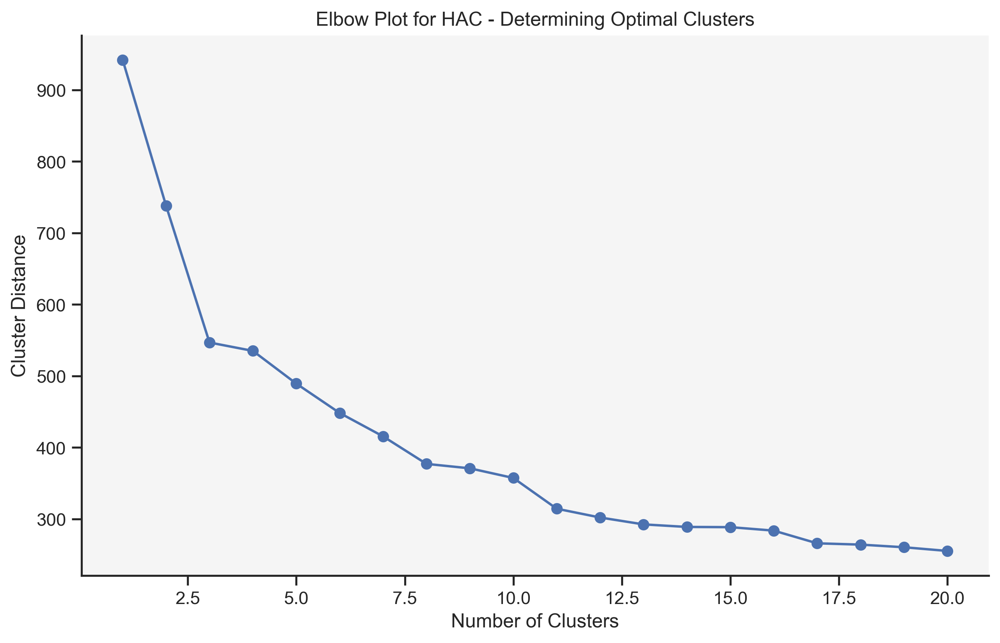

In [13]:
###############################
## PERFORM HAC ON EMBEDDINGS ##
###############################

## Perform hierarchical agglomerative clustering (HAC) on the high-dimensional embeddings
linkage_matrix = linkage(embeddings, method='ward')  ## Using Ward's method for clustering

## Elbow plot to determine the optimal number of clusters
last = linkage_matrix[-20:, 2]
last_rev = last[::-1]
idxs = np.arange(1, len(last) + 1)
plt.figure(figsize=(10, 6))
plt.plot(idxs, last_rev, marker="o")
plt.title('Elbow Plot for HAC - Determining Optimal Clusters')
plt.xlabel('Number of Clusters')
plt.ylabel('Cluster Distance')
plt.grid(False)
plt.gca().spines['top'].set_visible(False)
plt.gca().spines['right'].set_visible(False)
plt.show()

#
###

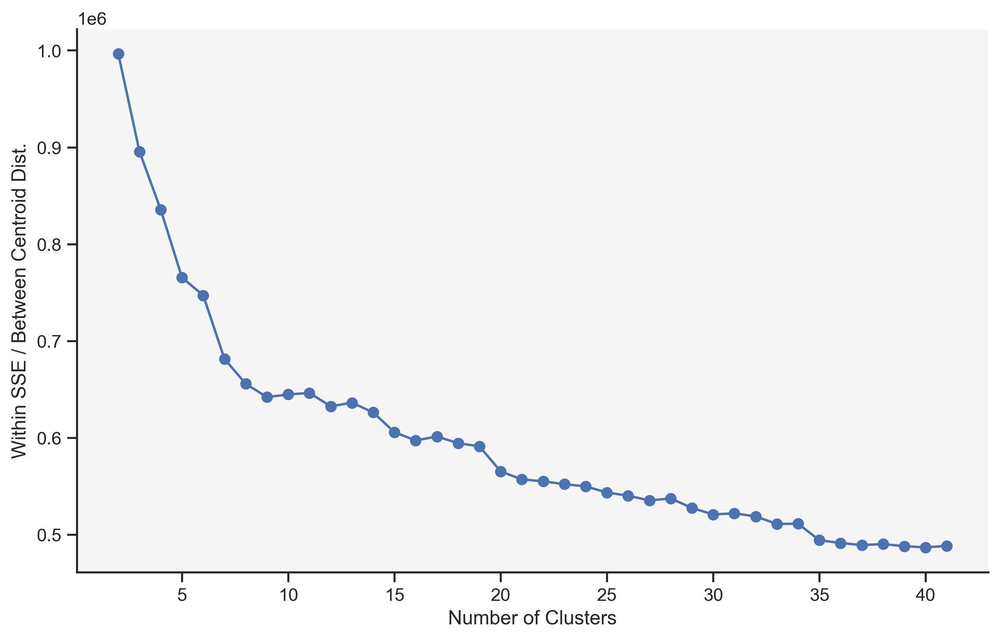

In [14]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.cluster.hierarchy import fcluster

# assume linkage_matrix and embeddings are already defined

last = linkage_matrix[-40:, 2][::-1]
ks = np.arange(2, len(last) + 2)   # start at 2 clusters

ratios = []
for k in ks:
    labels = fcluster(linkage_matrix, k, criterion='maxclust')
    # centroids
    uniq = np.unique(labels)
    centroids = np.vstack([embeddings[labels==ci].mean(axis=0)
                           for ci in uniq])
    # within-cluster SSE (scalar per cluster)
    w_sse = sum(
        np.sum((embeddings[labels==ci] - c)**2)
        for ci, c in zip(uniq, centroids)
    )
    # between-centroid mean distance
    dmat = np.sqrt(((centroids[:,None] - centroids[None,:])**2).sum(-1))
    i, j = np.triu_indices(len(uniq), k=1)
    b_mean = dmat[i,j].mean()            # now guaranteed non-empty for k>=2

    ratios.append(w_sse / b_mean)

plt.figure(figsize=(10,6))
plt.plot(ks, ratios, marker='o')
# plt.title('Elbow: Within‐SSE / Mean Between‐Centroid Distance')
plt.xlabel('Number of Clusters')
plt.ylabel('Within SSE / Between Centroid Dist.')
ax = plt.gca()
ax.spines['top'].set_visible(False)
ax.spines['right'].set_visible(False)
plt.show()

In [15]:
#######################################
## SELECT OPTIMAL NUMBER OF CLUSTERS ##
#######################################

## HAC parameters
num_clusters = 15  ## Set to the optimal number of clusters identified earlier

## Assign cluster labels based on the specified number of clusters
cluster_labels = fcluster(linkage_matrix, num_clusters, criterion='maxclust')

## Check the result
print(f'Cluster labels assigned to {len(cluster_labels)} images')

#
###

Cluster labels assigned to 20000 images


In [16]:
#########################################
## SAVE EMBEDDINGS AND CLUSTER LABELS  ##
#########################################

## Create a dataframe to store the embeddings and their corresponding cluster labels
clustered_data = pd.DataFrame({
    'filename': image_filenames,
    'cluster_label': cluster_labels
})

## Save the cluster labels to a CSV file
output_path = pti + 'image_identifiers_and_reference_clusters.csv'  ## Replace with your desired output path
clustered_data.to_csv(output_path, index=False)

## End
print(f'Clustered data saved to {output_path}')

#
###

Clustered data saved to /Volumes/Elements/BDI/projects/GSG/outputs/o3_mil/icgc-c/model_vit_icgcc_raw_FTL_0/aggregator_pawmil_1000/singletask-relapse/predictions/image_identifiers_and_reference_clusters.csv


In [17]:
###########################
## APPLY t-SNE REDUCTION ##
###########################

## Local imports
from sklearn.manifold import TSNE

## t-SNE parameters
n_components = 2  ## Set to 3 for 3D visualization
perplexity = 30  # Similar to UMAP's n_neighbors
learning_rate = 200  # Default recommended learning rate
random_state = 42

## Initialize t-SNE reducer
tsne_reducer = TSNE(n_components=n_components, perplexity=perplexity, learning_rate=learning_rate, random_state=random_state)

## Fit and transform the embeddings
reduced_embeddings = tsne_reducer.fit_transform(embeddings)

## Check the shape of the reduced embeddings
print(f'Reduced embeddings shape: {reduced_embeddings.shape}')

#
###

Reduced embeddings shape: (20000, 2)


In [18]:
###################
## FORMAT SCORES ##
###################

scores = (np.array(scores_low)>0)*1 - (np.array(scores_hig)<0)*1

#
###

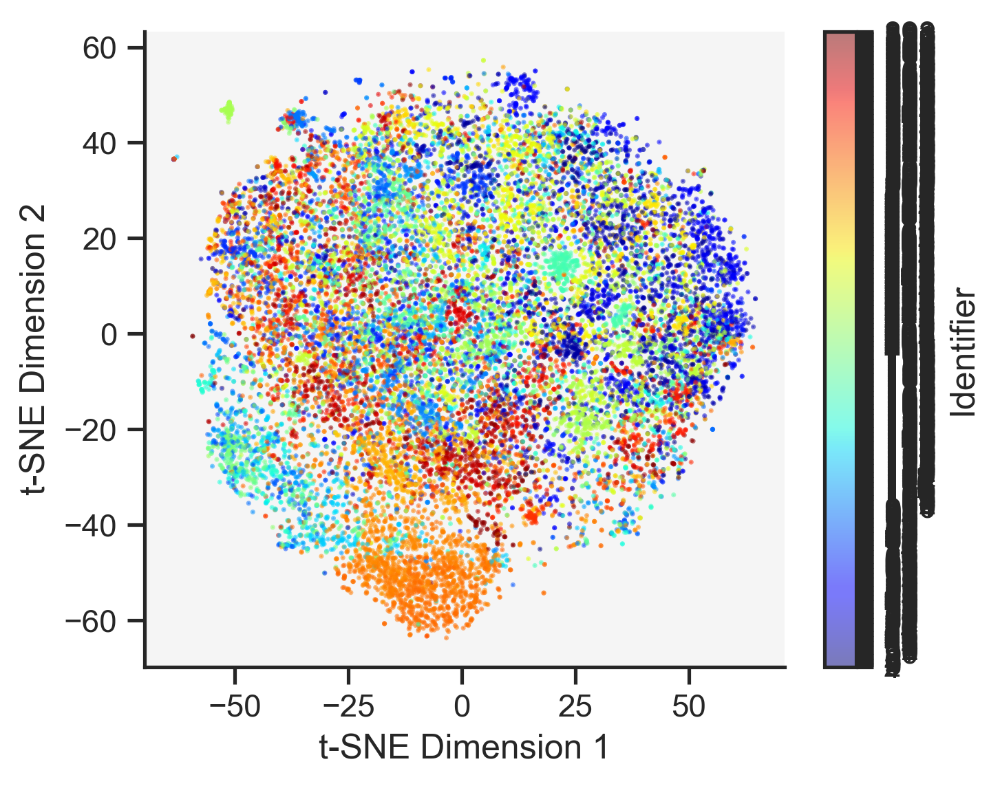

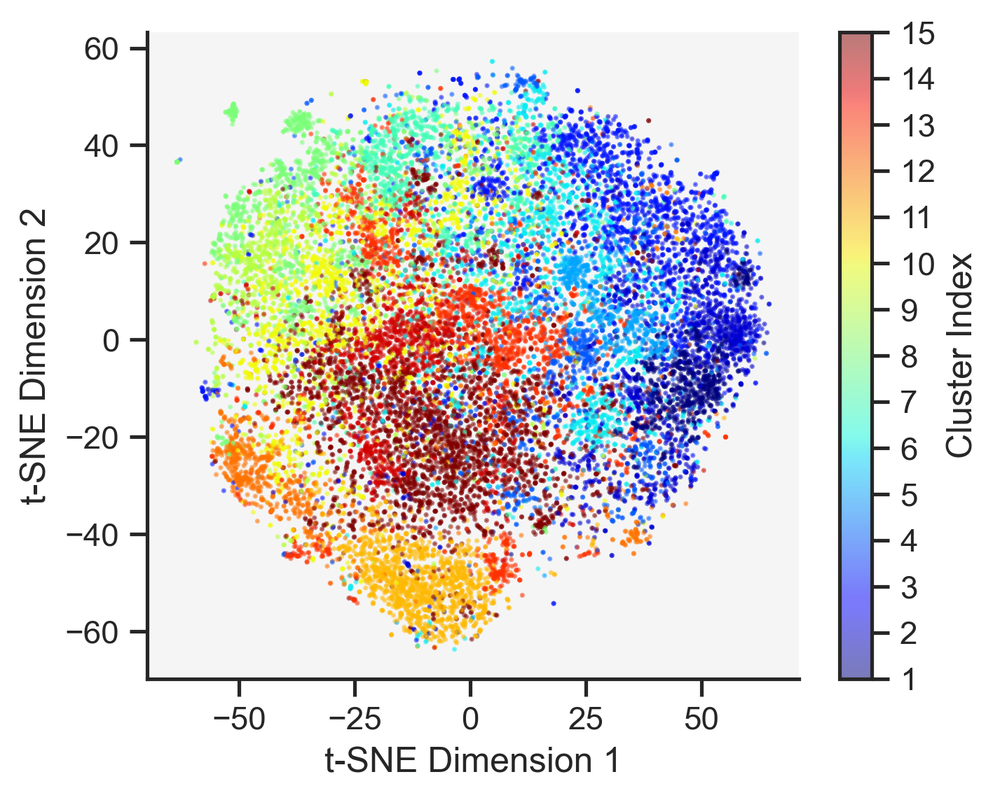

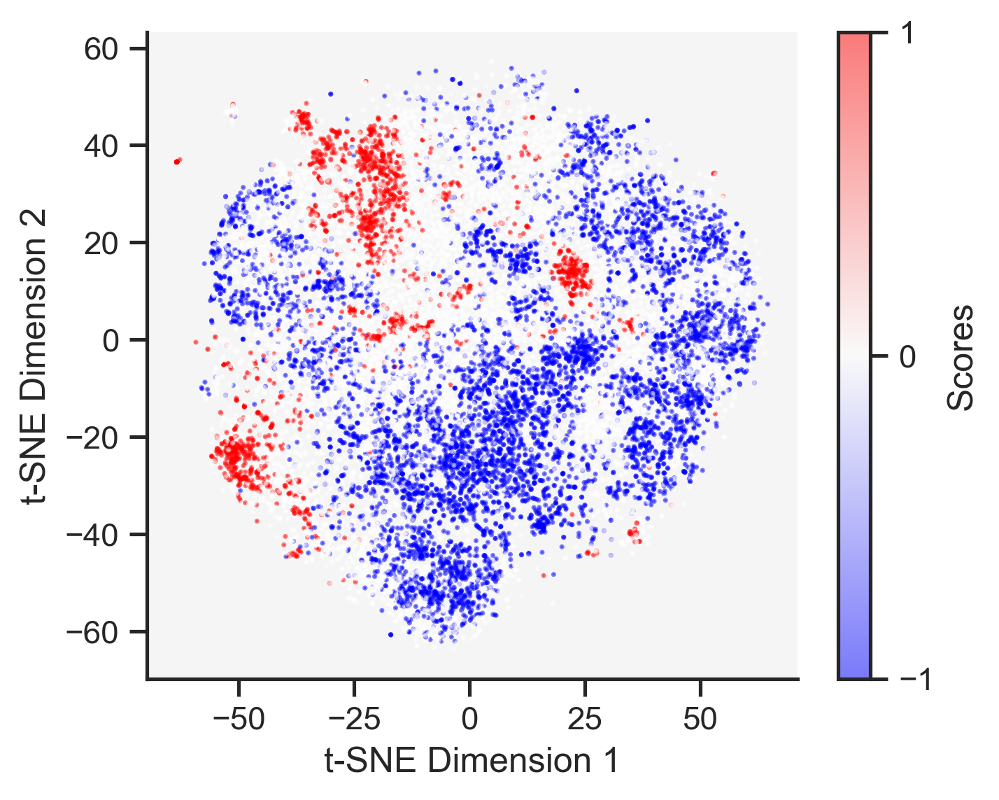

In [19]:
##############################################
## UPDATE t-SNE VISUALIZATION WITH CLUSTERS ##
##############################################

## Parameters
FIGSIZE = (5,4)
POINTSIZE = .5
ALPHA = 0.5

## t-SNE with ID
plt.figure(figsize=FIGSIZE)    
scatter = plt.scatter(reduced_embeddings[:, 0], reduced_embeddings[:, 1], 
                      c=numeric_ids + 1, cmap='jet', s=POINTSIZE, alpha=ALPHA)    
plt.xlabel('t-SNE Dimension 1')
plt.ylabel('t-SNE Dimension 2')
plt.grid(False)
plt.colorbar(scatter, ticks=range(1, num_groups + 1), label='Identifier')
plt.gca().spines['top'].set_visible(False)
plt.gca().spines['right'].set_visible(False)
plt.show()

## t-SNE with cluster index
plt.figure(figsize=FIGSIZE)
scatter = plt.scatter(reduced_embeddings[:, 0], reduced_embeddings[:, 1], 
                      c=cluster_labels, cmap='jet', s=POINTSIZE, alpha=ALPHA)    
plt.xlabel('t-SNE Dimension 1')
plt.ylabel('t-SNE Dimension 2')
plt.grid(False)
plt.colorbar(scatter, ticks=range(1, num_clusters + 1), label='Cluster Index')
plt.gca().spines['top'].set_visible(False)
plt.gca().spines['right'].set_visible(False)
plt.show()

## t-SNE with relapse
plt.figure(figsize=FIGSIZE)
scatter = plt.scatter(reduced_embeddings[:, 0], reduced_embeddings[:, 1], 
                      c=scores, cmap='bwr', s=POINTSIZE, alpha=ALPHA)    
plt.xlabel('t-SNE Dimension 1')
plt.ylabel('t-SNE Dimension 2')
plt.grid(False)
plt.colorbar(scatter, ticks=range(-1,1+1), label='Scores')
plt.gca().spines['top'].set_visible(False)
plt.gca().spines['right'].set_visible(False)
plt.show()

#
###

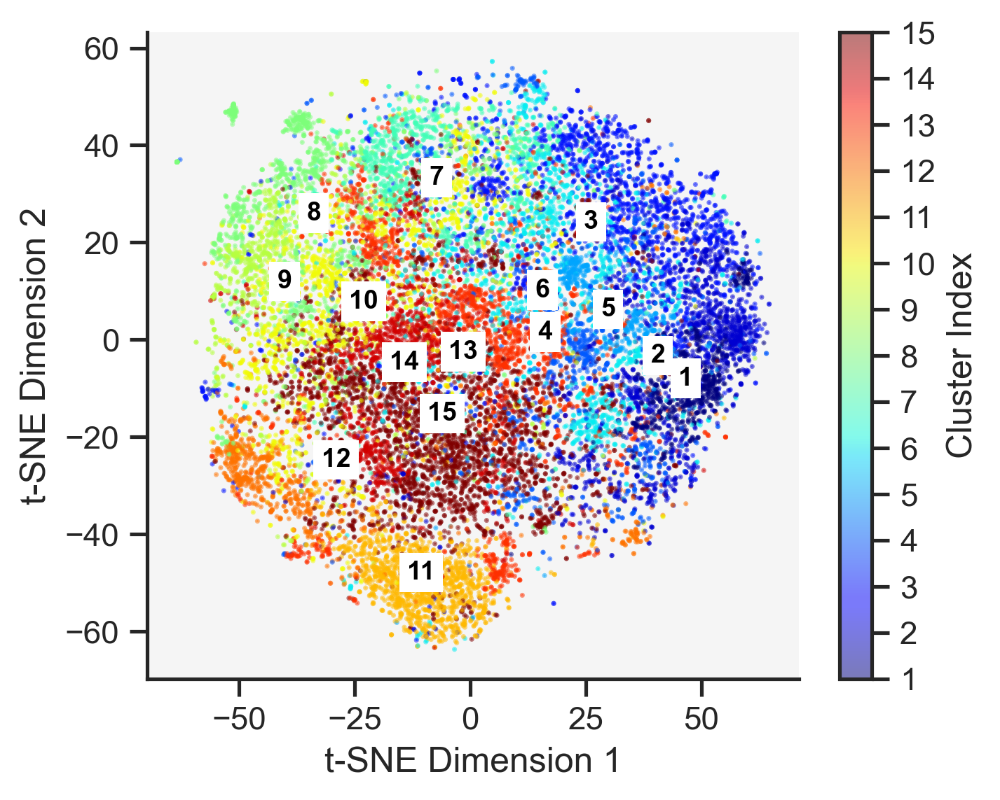

In [20]:
plt.figure(figsize=FIGSIZE)
scatter = plt.scatter(reduced_embeddings[:, 0], reduced_embeddings[:, 1], 
                      c=cluster_labels, cmap='jet', s=POINTSIZE, alpha=ALPHA)    
plt.xlabel('t-SNE Dimension 1')
plt.ylabel('t-SNE Dimension 2')
plt.grid(False)

for cluster_id in np.unique(cluster_labels):
    cluster_points = reduced_embeddings[cluster_labels == cluster_id]
    centroid = cluster_points.mean(axis=0)
    plt.text(centroid[0], centroid[1], str(cluster_id),
             fontsize=9, fontweight='bold', ha='center', va='center', color='black',
             bbox=dict(facecolor='white', edgecolor='none', boxstyle='square,pad=0.3'))

plt.colorbar(scatter, ticks=range(1, num_clusters + 1), label='Cluster Index')
plt.gca().spines['top'].set_visible(False)
plt.gca().spines['right'].set_visible(False)
plt.show()

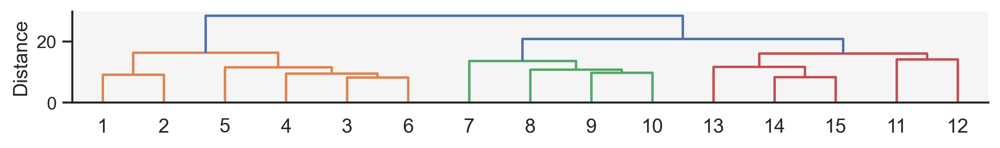

[1, 2, 5, 4, 3, 6, 7, 8, 9, 10, 13, 14, 15, 11, 12]


In [21]:
######################################
## VISUALIZE DENDROGRAM OF CLUSTERS ##
######################################

from scipy.cluster.hierarchy import dendrogram

## Compute cluster centroids
cluster_centroids = []
for cluster_idx in range(1, num_clusters + 1):
    cluster_embeddings = [embeddings[i] for i in range(len(cluster_labels)) if cluster_labels[i] == cluster_idx]
    cluster_centroid = np.mean(cluster_embeddings, axis=0)
    cluster_centroids.append(cluster_centroid)

## Compute linkage matrix for hierarchical clustering
linkage_matrix = linkage(cluster_centroids, method='ward')

## Plot dendrogram
plt.figure(figsize=(10, 1))
dendro = dendrogram(linkage_matrix, labels=[f'{i+1}' for i in range(num_clusters)], leaf_rotation=0, leaf_font_size=12)
# plt.title('Hierarchical Clustering Dendrogram')
# plt.xlabel('Cluster')
plt.ylabel('Distance')
plt.gca().spines['top'].set_visible(False)
plt.gca().spines['right'].set_visible(False)
plt.show()

## Fix cluster order
cluster_order = [int(_.replace('Cluster ','')) for _ in dendro['ivl']]
print(cluster_order)
# cluster_order = [6, 2, 4, 3, 7, 1, 5]

#
###

Cluster index: 1, number samples: 10
Cluster index: 2, number samples: 18
Cluster index: 5, number samples: 13
Cluster index: 4, number samples: 10
Cluster index: 3, number samples: 14
Cluster index: 6, number samples: 20
Cluster index: 7, number samples: 14
Cluster index: 8, number samples: 19
Cluster index: 9, number samples: 18
Cluster index: 10, number samples: 16
Cluster index: 13, number samples: 14
Cluster index: 14, number samples: 13
Cluster index: 15, number samples: 10
Cluster index: 11, number samples: 1
Cluster index: 12, number samples: 7


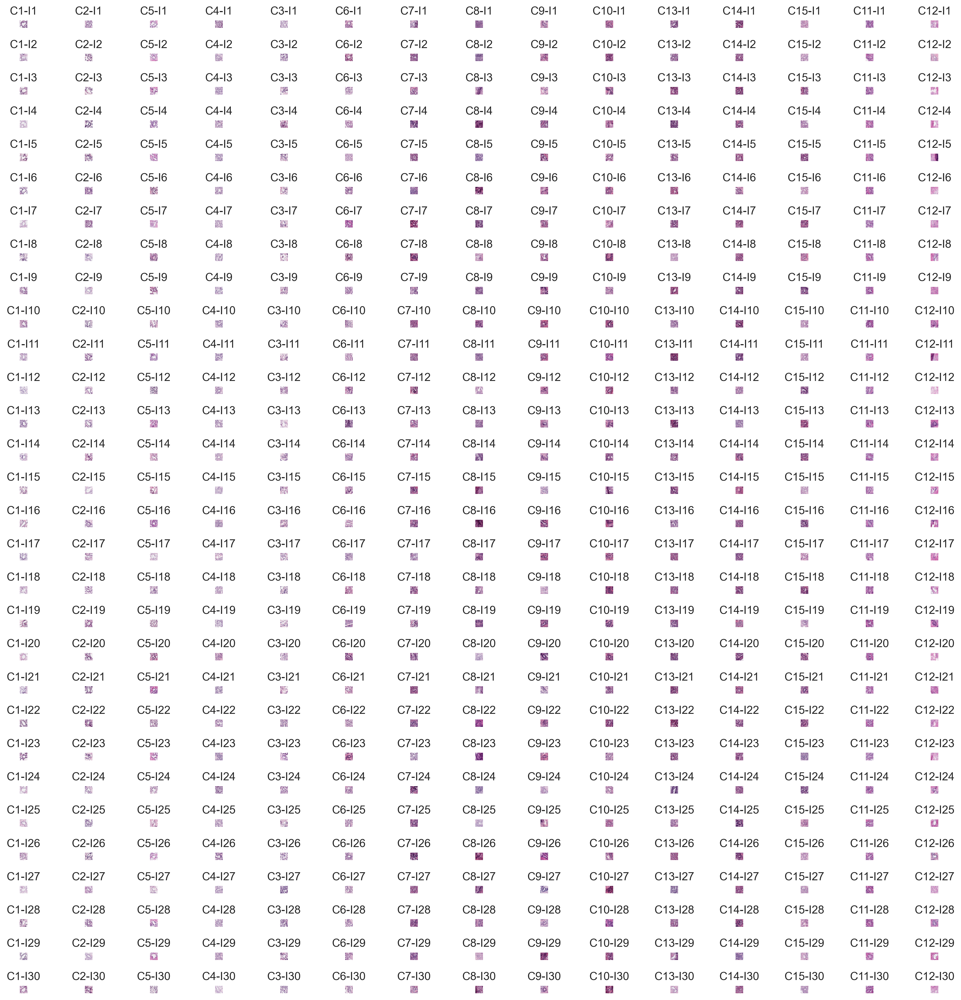

In [43]:
##########################################
## PICK AND SHOW EXAMPLES FROM CLUSTERS ##
##########################################

examples_per_cluster = 30  ## Number of examples to show per cluster
output_dir = "/Volumes/Elements/BDI/projects/GSG/outputs/o5_phenotyper/clusters-icgc-c-vit-raw-FTL0-BCR"
os.makedirs(output_dir, exist_ok=True)
WRITE_FILES = False

## Initialize figure for examples
fig, axs = plt.subplots(examples_per_cluster, num_clusters, figsize=(15, 15))

## Loop over clusters
k = 0
for cluster_idx in cluster_order:
# for cluster_idx in range(1, num_clusters + 1):    
    
    ## Get all indices in the current cluster
    cluster_indices = [i for i in range(len(cluster_labels)) if cluster_labels[i] == cluster_idx]
    cluster_files = [image_filenames[i] for i in cluster_indices]
    cluster_embeddings = [embeddings[i] for i in cluster_indices]
    cluster_scores = [scores[i] for i in cluster_indices]
    
    ## Compute distances to centroid
    distances = pairwise_distances(cluster_embeddings, [cluster_centroids[cluster_idx - 1]])
    closest_indices = np.argsort(distances[:, 0])[:examples_per_cluster]
    selected_files = np.array(cluster_files)[closest_indices]
    selected_scores = np.array(cluster_scores)[closest_indices]

    ## Save scores
    selected_names = np.array([f'C{cluster_idx}_I{i}' for i in range(len(selected_files))])[:,None]
    selected_metadata = np.concatenate((selected_names, selected_scores), axis=1)
    df = pd.DataFrame(selected_metadata)
    df.to_csv(output_dir + f'_C{cluster_idx}_scores.csv', index=False)

    ## Load and display each example
    for example_idx, filename in enumerate(selected_files):
        image_path = f'{dataset_path}/{filename}'
        image_path = image_path.replace('_mask_both','_raw')
        image = Image.open(image_path)
        #
        axs[example_idx, k].imshow(image)
        axs[example_idx, k].axis('off')
        axs[example_idx, k].set_title(f'C{cluster_idx}-I{example_idx + 1}')
        #
        ## Save examples
        if WRITE_FILES:
            image.save(os.path.join(output_dir, f'C{cluster_idx}-I{example_idx + 1}.png'))
        
    ## Print number of unique slides
    group_ids = [f.split("_V")[0] for f in selected_files]
    print(f"Cluster index: {cluster_idx}, number samples: {len(np.unique(group_ids)):.0f}")    

    ## Column index
    k += 1

plt.tight_layout()
plt.show()

#
###

In [ ]:
##########################################
## PICK AND SHOW EXAMPLES FROM CLUSTERS ##
##########################################

examples_per_cluster = 15  ## Number of examples to show per cluster

## Initialize figure for examples
fig, axs = plt.subplots(examples_per_cluster, num_clusters, figsize=(15, 15))

## Loop over clusters
k = 0
for cluster_idx in cluster_order:
# for cluster_idx in range(1, num_clusters + 1):    
    
    ## Get all indices in the current cluster
    cluster_indices = [i for i in range(len(cluster_labels)) if cluster_labels[i] == cluster_idx]
    cluster_files = [image_filenames[i] for i in cluster_indices]
    cluster_embeddings = [embeddings[i] for i in cluster_indices]
    
    ## Compute distances to centroid
    distances = pairwise_distances(cluster_embeddings, [cluster_centroids[cluster_idx - 1]])
    closest_indices = np.argsort(distances[:, 0])[:examples_per_cluster]
    selected_files = np.array(cluster_files)[closest_indices]

    ## Load and display each example
    for example_idx, filename in enumerate(selected_files):
        image_path = f'{dataset_path}/{filename}'
        image_path = image_path.replace('_raw','_mask_both')
        image = Image.open(image_path)
        #
        axs[example_idx, k].imshow(image)
        axs[example_idx, k].axis('off')
        axs[example_idx, k].set_title(f'C{cluster_idx}-I{example_idx + 1}')

    ## Column index
    k += 1

plt.tight_layout()
plt.show()

#
###

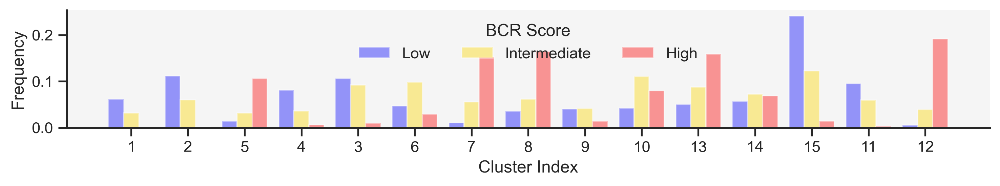

In [37]:
##################################
## CLUSTER DISTRIBUTION ORDERED ##
##################################

## Parameters
LABEL_NAME = 'BCR Score'
LEVELS = ['Low', 'Intermediate', 'High']

## Convert to a DataFrame for easier manipulation
data = pd.DataFrame({
    'Cluster': cluster_labels,
    'Identifier': (scores).flatten(),
})

## Get the unique clusters and identifiers
unique_clusters = sorted(data['Cluster'].unique())
unique_identifiers = sorted(data['Identifier'].unique())

## Count the frequency of clusters for each identifier
frequency_table = data.groupby(['Identifier', 'Cluster']).size().unstack(fill_value=0)

## Normalize the frequencies if needed (e.g., proportions instead of counts)
frequency_table = frequency_table.div(frequency_table.sum(axis=1), axis=0)

# Reorder the columns of the frequency table according to cluster_order
frequency_table = frequency_table[cluster_order]

# Plot settings
bar_width = 0.8 / len(unique_identifiers)
x_offsets = np.linspace(
    -bar_width * (len(unique_identifiers) - 1) / 2,
     bar_width * (len(unique_identifiers) - 1) / 2,
     len(unique_identifiers)
)

x_positions = np.arange(len(cluster_order))  # numerical x-positions

# Plot
plt.figure(figsize=(10, 2))
color_vector = ['blue','gold','red']
# color_vector = ['royalblue','lightgrey','salmon']
for idx, identifier in enumerate(unique_identifiers):
    frequencies = frequency_table.loc[identifier]
    plt.bar(
        x_positions + x_offsets[idx],  # shifted numeric positions
        frequencies,
        width=bar_width,
        alpha=0.4,
        color=color_vector[identifier + 1],
        label=LEVELS[identifier + 1]
    )

# Final tweaks
plt.xlabel('Cluster Index')
plt.ylabel('Frequency')
plt.xticks(ticks=x_positions, labels=cluster_order)  # set custom labels
plt.legend(title=LABEL_NAME, loc='upper center', ncol=3, frameon=False)
plt.gca().spines['top'].set_visible(False)
plt.gca().spines['right'].set_visible(False)
plt.tight_layout()
plt.show()

#
###

In [25]:
###############################
## FUNCTIONS FOR PHENOTYPING ##
###############################

def binarise_image(image, thresholds=[30,30,30]):
    """
    Binarise image based on threshold for each channels.
    """
    for i in range(3):
        image[:,:,i] = (image[:,:,i] > thresholds[i])
    return image

def isolate_focal_gland(epithelial_prob, lumen_prob, threshold=0.5):
    """
    Isolates the focal gland in an image based on epithelial and luminal probability maps.
    """
    ## Step 1: Binarize the probability maps
    epithelial_mask = (epithelial_prob >= threshold).astype(np.uint8)
    lumen_mask = (lumen_prob >= threshold).astype(np.uint8)
    
    ## Step 2: Combine the binary masks to create a gland mask
    gland_mask = np.logical_or(epithelial_mask, lumen_mask).astype(np.uint8)
    
    # Step 3: Find connected components
    num_labels, labels, stats, centroids = cv2.connectedComponentsWithStats(gland_mask, connectivity=8)
    
    ## Step 4: Identify the connected component containing the image center
    H, W = gland_mask.shape
    center_x, center_y = W // 2, H // 2
    
    focal_label = None
    for label in range(1, num_labels):  # Skipping background label (0)
        x, y, w, h, area = stats[label]
        if x <= center_x < x + w and y <= center_y < y + h:
            focal_label = label
            break
    
    if focal_label is not None:
        ## Step 5: Generate the final gland mask
        focal_gland_mask = (labels == focal_label).astype(np.uint8)
    else:
        ## If no gland is found at the center, return an empty mask
        focal_gland_mask = np.zeros_like(gland_mask, dtype=np.uint8)
    
    return focal_gland_mask

def compute_features(image, gland_mask):
    """
    Computes relative area and shape analysis features from the given binarized image and gland mask.
    """
    features = {}
    H, W = image.shape[:2]
    total_pixels = H * W
    
    nuclei_mask = image[:,:,0]
    epithelial_mask = image[:,:,1]
    lumen_mask = (1 - gland_mask) * epithelial_mask # image[:,:,2]

    # features['area'] = np.sum(gland_mask)
    
    ## Compute relative area features    
    features['relative_area_nuclei'] = np.sum(nuclei_mask) / total_pixels
    features['relative_area_epithelia'] = np.sum(epithelial_mask) / total_pixels
    features['relative_area_lumen'] = np.sum(lumen_mask) / total_pixels
    features['relative_area_epithelial_nuclei'] = np.sum(nuclei_mask * epithelial_mask) / total_pixels
    features['relative_area_non_epithelial_nuclei'] = np.sum(nuclei_mask * (1 - gland_mask)) / total_pixels
    
    ## Shape analysis features
    gland_contours, _ = cv2.findContours(gland_mask, cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_SIMPLE)
    if gland_contours:
        cnt = max(gland_contours, key=cv2.contourArea)        
        # features['area'] = cv2.contourArea(cnt)
        features['perimeter'] = cv2.arcLength(cnt, True)        
        # hull = cv2.convexHull(cnt)
        # features['convex_hull_area'] = cv2.contourArea(hull)
        # features['compactness'] = features['area'] / features['convex_hull_area'] if features['convex_hull_area'] > 0 else 0        
        # features['roundness'] = (4 * np.pi * features['area']) / (features['perimeter']**2) if features['perimeter'] > 0 else 0
    else:
        features.update({# 'area': 0, 
                         'perimeter': 0, 
                         # 'convex_hull_area': 0, 
                         # 'compactness': 0,
                         # 'roundness': 0,
        })
    
    return features

#
###

In [26]:
########################
## PHENOTYPE CLUSTERS ##
########################

## Initialize storage for features
examples_per_cluster = 100  ## Number of examples to show per cluster
cluster_feature_data = []

## Compute cluster centroids
cluster_centroids = []
for cluster_idx in range(1, num_clusters + 1):
    cluster_embeddings = [embeddings[i] for i in range(len(cluster_labels)) if cluster_labels[i] == cluster_idx]
    cluster_centroid = np.mean(cluster_embeddings, axis=0)
    cluster_centroids.append(cluster_centroid)

## Loop over clusters
for cluster_idx in range(1, num_clusters + 1):
    
    ## Get all indices in the current cluster
    cluster_indices = [i for i in range(len(cluster_labels)) if cluster_labels[i] == cluster_idx]
    cluster_files = [image_filenames[i] for i in cluster_indices]
    cluster_embeddings = [embeddings[i] for i in cluster_indices]
    
    ## Compute distances to centroid
    distances = pairwise_distances(cluster_embeddings, [cluster_centroids[cluster_idx - 1]])
    closest_indices = np.argsort(distances[:, 0])[:examples_per_cluster]
    selected_files = np.array(cluster_files)[closest_indices]
    
    ## Process each selected image
    for filename in selected_files:
        image_path = f'{dataset_path}/{filename}'
        image_path = image_path.replace('_raw','_mask_both')
        image = np.array(Image.open(image_path))
        
        ## Binarize image
        image = binarise_image(image)
        
        ## Get gland mask
        mask = isolate_focal_gland(image[:,:,0], image[:,:,1])
        
        ## Compute features
        features = compute_features(image, mask)
        features['cluster'] = cluster_idx  # Assign cluster label
        cluster_feature_data.append(features)

## Convert feature data to DataFrame
feature_df = pd.DataFrame(cluster_feature_data)

#
###

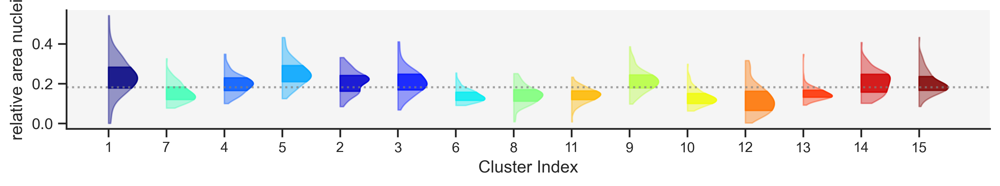

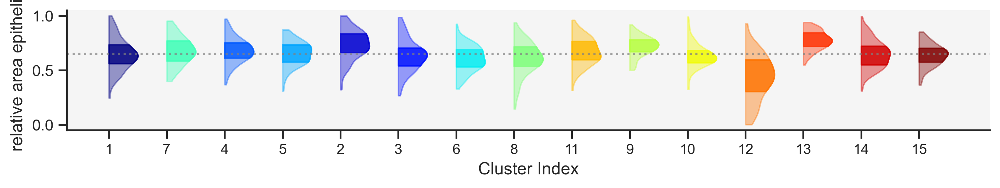

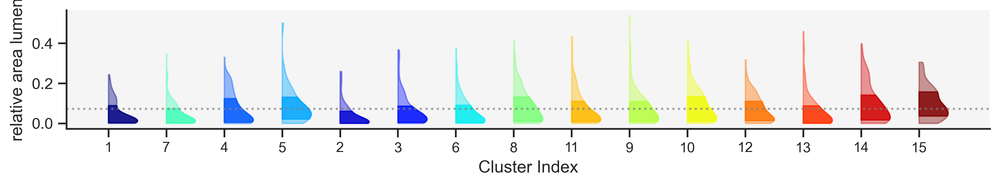

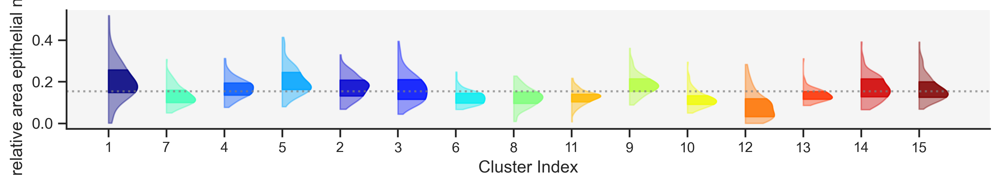

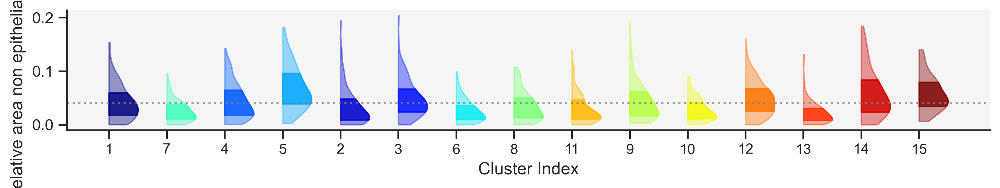

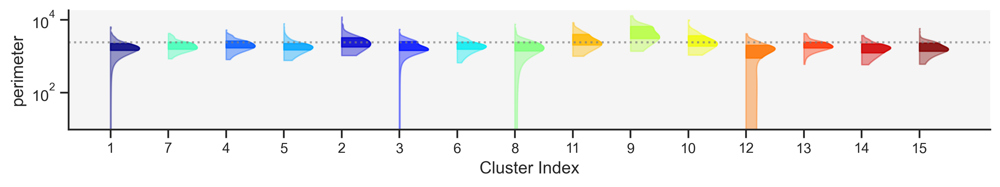

In [27]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.stats import gaussian_kde

####################################
## VISUALISE FEATURE DISTRIBUTION ##
####################################

## Get unique clusters and number of features
feature_names = feature_df.columns[:-1]  # Exclude 'cluster' column
num_features = len(feature_names)
clusters = sorted(feature_df['cluster'].unique())  # Ensure ordered clusters
clusters = cluster_order
num_clusters = len(clusters)

## Get colors from the 'jet' colormap
cmap = plt.get_cmap('jet')
colors = [cmap(i / (num_clusters - 1)) for i in range(num_clusters)]
colors = [colors[i-1] for i in clusters]  # Ordered colors

for feature in feature_names:
    plt.figure(figsize=(10, 2))
    ax = plt.gca()  # Get current axis

    for j, cluster in enumerate(clusters):
        cluster_data = feature_df[feature_df['cluster'] == cluster][feature].dropna()
        if len(cluster_data) < 2:
            continue

        kde = gaussian_kde(cluster_data, bw_method='scott')
        x_vals = np.linspace(cluster_data.min(), cluster_data.max(), 300)
        y_vals = kde(x_vals)
        y_vals = y_vals / y_vals.max() * 0.5

        p2_5, p25, p75, p97_5 = np.percentile(cluster_data, [2.5, 25, 75, 97.5])
        mask = (x_vals >= p25) & (x_vals <= p75)

        cluster_x_offset = j

        ax.fill_betweenx(x_vals, cluster_x_offset, cluster_x_offset + y_vals, color=colors[j], alpha=0.4)
        ax.fill_betweenx(x_vals[mask], cluster_x_offset, cluster_x_offset + y_vals[mask], color=colors[j], alpha=0.8, label="IQR" if j == 0 else "")

    mean_value = feature_df[feature].mean()
    ax.axhline(mean_value, color='grey', linestyle='dotted', linewidth=1.5, alpha=0.7, label="Mean")

    formatted_feature_name = feature.replace('_', ' ')
    ax.set_ylabel(formatted_feature_name, fontsize=12)
    ax.set_xticks(range(num_clusters))
    ax.set_xticklabels(clusters, fontsize=10)
    ax.set_xlabel("Cluster Index", fontsize=12)

    if feature in ['area', 'perimeter', 'convex_hull_area']:
        ax.set(yscale="log")

    ax.spines['top'].set_visible(False)
    ax.spines['right'].set_visible(False)

    plt.tight_layout()
    plt.show()


In [28]:
"""
###########################
## SAVE DATA TO CSV FILE ##
###########################

import pandas as pd

## Assemble data into a dictionary with properly formatted bounding box coordinates
data_dict = {
    "image_filenames": image_filenames,
    "image_filenames_short": image_filenames_short,    
    "numeric_ids": numeric_ids,
    "min_x": [coord[0] for coord in image_coords],  # Extract min_x
    "max_x": [coord[1] for coord in image_coords],  # Extract max_x
    "min_y": [coord[2] for coord in image_coords],  # Extract min_y
    "max_y": [coord[3] for coord in image_coords],  # Extract max_y
    "image_coords_short_x": [coord[0] for coord in image_coords_short],  # Short X (centered)
    "image_coords_short_y": [coord[1] for coord in image_coords_short],  # Short Y (centered)
    "cluster_labels": cluster_labels,
    "scores": ((np.array(scores_mid)>0)*1).flatten(),
}

## Convert to DataFrame
df_output = pd.DataFrame(data_dict)

## Define output file path
output_csv_path = pti + 'summary_reference_clusters.csv'

## Save DataFrame to CSV
df_output.to_csv(output_csv_path, index=False)

print(f"Saved clustered image data to {output_csv_path}")

#
###
"""

'\n###########################\n## SAVE DATA TO CSV FILE ##\n###########################\n\nimport pandas as pd\n\n## Assemble data into a dictionary with properly formatted bounding box coordinates\ndata_dict = {\n    "image_filenames": image_filenames,\n    "image_filenames_short": image_filenames_short,    \n    "numeric_ids": numeric_ids,\n    "min_x": [coord[0] for coord in image_coords],  # Extract min_x\n    "max_x": [coord[1] for coord in image_coords],  # Extract max_x\n    "min_y": [coord[2] for coord in image_coords],  # Extract min_y\n    "max_y": [coord[3] for coord in image_coords],  # Extract max_y\n    "image_coords_short_x": [coord[0] for coord in image_coords_short],  # Short X (centered)\n    "image_coords_short_y": [coord[1] for coord in image_coords_short],  # Short Y (centered)\n    "cluster_labels": cluster_labels,\n    "scores": ((np.array(scores_mid)>0)*1).flatten(),\n}\n\n## Convert to DataFrame\ndf_output = pd.DataFrame(data_dict)\n\n## Define output file pat

In [29]:
"""
############################################
## PLOT FILTERED DATA BY CLUSTER LABEL ##
############################################

import matplotlib.pyplot as plt

## Filter the DataFrame for the specific case
filtered_df = df_output[df_output["image_filenames_short"] == "TCGA-2A-A8VL-01A_1"]

## Scatter plot
plt.figure(figsize=(10, 8))  
#
scatter = plt.scatter(
    filtered_df["image_coords_short_y"],
    filtered_df["image_coords_short_x"],
    c=filtered_df["cluster_labels"],  # Color by cluster labels
    cmap="jet",
    # edgecolors="k",
    alpha=1.0,
    s=1
)
#
## Add a colorbar
plt.colorbar(scatter, label="Cluster Label")
#
## Labels and title
plt.xlabel("Image Coords Short Y")
plt.ylabel("Image Coords Short X")
# plt.title("Spatial Distribution of Clustered Glands for TCGA-HC-A6AP")
#
## Invert Y-axis (if needed, depending on image origin)
plt.gca().invert_yaxis()
#
##
sns.despine()
#
## End
plt.show()

## Scatter plot
plt.figure(figsize=(10, 8))  
#
scatter = plt.scatter(
    filtered_df["image_coords_short_y"],
    filtered_df["image_coords_short_x"],
    c=filtered_df["scores"],  # Color by cluster labels
    cmap="bwr",
    # edgecolors="k",
    alpha=1.0,
    s=1
)
#
## Add a colorbar
plt.colorbar(scatter, label="Score")
#
## Labels and title
plt.xlabel("Image Coords Short Y")
plt.ylabel("Image Coords Short X")
# plt.title("Spatial Distribution of Clustered Glands for TCGA-HC-A6AP")
#
## Invert Y-axis (if needed, depending on image origin)
plt.gca().invert_yaxis()
#
##
sns.despine()
#
## End
plt.show()

#
###
"""

'\n############################################\n## PLOT FILTERED DATA BY CLUSTER LABEL ##\n############################################\n\nimport matplotlib.pyplot as plt\n\n## Filter the DataFrame for the specific case\nfiltered_df = df_output[df_output["image_filenames_short"] == "TCGA-2A-A8VL-01A_1"]\n\n## Scatter plot\nplt.figure(figsize=(10, 8))  \n#\nscatter = plt.scatter(\n    filtered_df["image_coords_short_y"],\n    filtered_df["image_coords_short_x"],\n    c=filtered_df["cluster_labels"],  # Color by cluster labels\n    cmap="jet",\n    # edgecolors="k",\n    alpha=1.0,\n    s=1\n)\n#\n## Add a colorbar\nplt.colorbar(scatter, label="Cluster Label")\n#\n## Labels and title\nplt.xlabel("Image Coords Short Y")\nplt.ylabel("Image Coords Short X")\n# plt.title("Spatial Distribution of Clustered Glands for TCGA-HC-A6AP")\n#\n## Invert Y-axis (if needed, depending on image origin)\nplt.gca().invert_yaxis()\n#\n##\nsns.despine()\n#\n## End\nplt.show()\n\n## Scatter plot\nplt.figure(

In [30]:
"""
#######################
## FILTER EMBEDDINGS ##
#######################

## Remove files from data
index = np.argwhere((cluster_labels != 5) & (cluster_labels != 6)).flatten()
embeddings = embeddings[index]
reduced_embeddings = reduced_embeddings[index]
cluster_labels = cluster_labels[index]
numeric_ids = numeric_ids[index]
image_filenames = np.array(image_filenames)[index]

#
###
"""

'\n#######################\n## FILTER EMBEDDINGS ##\n#######################\n\n## Remove files from data\nindex = np.argwhere((cluster_labels != 5) & (cluster_labels != 6)).flatten()\nembeddings = embeddings[index]\nreduced_embeddings = reduced_embeddings[index]\ncluster_labels = cluster_labels[index]\nnumeric_ids = numeric_ids[index]\nimage_filenames = np.array(image_filenames)[index]\n\n#\n###\n'

In [31]:
"""
######################
## PHENOTYPE GLANDS ##
######################

## Load image
image_path = f'{dataset_path}/{image_filenames[10]}'
image = np.array(Image.open(image_path))

## Binarise image
image = binarise_image(image)

## Get mask
mask = isolate_focal_gland(image[:,:,0], image[:,:,1])

## Visualise
plt.imshow(image * 255 * mask[:,:,None])

## Compute features
features = compute_features(image, mask)
print(features)

#
###
"""

"\n######################\n## PHENOTYPE GLANDS ##\n######################\n\n## Load image\nimage_path = f'{dataset_path}/{image_filenames[10]}'\nimage = np.array(Image.open(image_path))\n\n## Binarise image\nimage = binarise_image(image)\n\n## Get mask\nmask = isolate_focal_gland(image[:,:,0], image[:,:,1])\n\n## Visualise\nplt.imshow(image * 255 * mask[:,:,None])\n\n## Compute features\nfeatures = compute_features(image, mask)\nprint(features)\n\n#\n###\n"

In [32]:
"""
##########################################
## PICK AND SHOW EXAMPLES FROM CLUSTERS ##
##########################################

## Initialize figure for examples
fig, axs = plt.subplots(examples_per_cluster, num_clusters, figsize=(15, 15))

## Loop over clusters
for cluster_idx in range(1, num_clusters + 1):
    
    ## Get all filenames in the current cluster
    cluster_files = [image_filenames[i] for i in range(len(cluster_labels)) if cluster_labels[i] == cluster_idx]
    
    ## Select a few examples from the cluster
    s = np.random.choice(len(cluster_files), examples_per_cluster, replace=False)
    selected_files = np.array(cluster_files)[s]
    # selected_files = cluster_files[:examples_per_cluster]  ## Adjust if there are fewer files    

    ## Load and display each example
    for example_idx, filename in enumerate(selected_files):
        image_path = f'{dataset_path}/{filename}'
        image = Image.open(image_path)
        axs[example_idx, cluster_idx - 1].imshow(image)
        axs[example_idx, cluster_idx - 1].axis('off')
        axs[example_idx, cluster_idx - 1].set_title(f'Cluster {cluster_idx}, Img {example_idx + 1}')

plt.tight_layout()
plt.show()

#
###
"""

"\n##########################################\n## PICK AND SHOW EXAMPLES FROM CLUSTERS ##\n##########################################\n\n## Initialize figure for examples\nfig, axs = plt.subplots(examples_per_cluster, num_clusters, figsize=(15, 15))\n\n## Loop over clusters\nfor cluster_idx in range(1, num_clusters + 1):\n    \n    ## Get all filenames in the current cluster\n    cluster_files = [image_filenames[i] for i in range(len(cluster_labels)) if cluster_labels[i] == cluster_idx]\n    \n    ## Select a few examples from the cluster\n    s = np.random.choice(len(cluster_files), examples_per_cluster, replace=False)\n    selected_files = np.array(cluster_files)[s]\n    # selected_files = cluster_files[:examples_per_cluster]  ## Adjust if there are fewer files    \n\n    ## Load and display each example\n    for example_idx, filename in enumerate(selected_files):\n        image_path = f'{dataset_path}/{filename}'\n        image = Image.open(image_path)\n        axs[example_idx, clus

In [33]:
"""
##########################
## APPLY UMAP REDUCTION ##
##########################

## Local imports
import umap

## UMAP parameters
n_neighbors = 30 // 2
min_dist = 0.1 // 2
n_components = 2  ## Set to 3 for 3D visualization

## Initialize UMAP reducer
umap_reducer = umap.UMAP(n_neighbors=n_neighbors, min_dist=min_dist, n_components=n_components, random_state=42)

## Fit and transform the embeddings
reduced_embeddings = umap_reducer.fit_transform(embeddings)

## Check the shape of the reduced embeddings
print(f'Reduced embeddings shape: {reduced_embeddings.shape}')

#
###
"""

"\n##########################\n## APPLY UMAP REDUCTION ##\n##########################\n\n## Local imports\nimport umap\n\n## UMAP parameters\nn_neighbors = 30 // 2\nmin_dist = 0.1 // 2\nn_components = 2  ## Set to 3 for 3D visualization\n\n## Initialize UMAP reducer\numap_reducer = umap.UMAP(n_neighbors=n_neighbors, min_dist=min_dist, n_components=n_components, random_state=42)\n\n## Fit and transform the embeddings\nreduced_embeddings = umap_reducer.fit_transform(embeddings)\n\n## Check the shape of the reduced embeddings\nprint(f'Reduced embeddings shape: {reduced_embeddings.shape}')\n\n#\n###\n"

In [34]:
"""
#############################################
## UPDATE UMAP VISUALIZATION WITH CLUSTERS ##
#############################################

## 2D Visualization with clusters
if n_components == 2:

    ## UMAP with ID
    plt.figure(figsize=(10, 8))    
    scatter = plt.scatter(reduced_embeddings[:, 0], reduced_embeddings[:, 1], 
                          c=numeric_ids, cmap='jet', s=5, alpha=0.75)    
    plt.xlabel('UMAP Dimension 1')
    plt.ylabel('UMAP Dimension 2')
    plt.grid(False)
    plt.colorbar(scatter, ticks=range(1, num_groups + 1), label='Identifier')
    plt.gca().spines['top'].set_visible(False)
    plt.gca().spines['right'].set_visible(False)
    plt.show()

    ## UMAP with cluster index
    plt.figure(figsize=(10, 8))
    scatter = plt.scatter(reduced_embeddings[:, 0], reduced_embeddings[:, 1], 
                          c=cluster_labels, cmap='jet', s=5, alpha=0.75)    
    plt.xlabel('UMAP Dimension 1')
    plt.ylabel('UMAP Dimension 2')
    plt.grid(False)
    plt.colorbar(scatter, ticks=range(1, num_clusters + 1), label='Cluster Index')
    plt.gca().spines['top'].set_visible(False)
    plt.gca().spines['right'].set_visible(False)
    plt.show()

#
###
"""

"\n#############################################\n## UPDATE UMAP VISUALIZATION WITH CLUSTERS ##\n#############################################\n\n## 2D Visualization with clusters\nif n_components == 2:\n\n    ## UMAP with ID\n    plt.figure(figsize=(10, 8))    \n    scatter = plt.scatter(reduced_embeddings[:, 0], reduced_embeddings[:, 1], \n                          c=numeric_ids, cmap='jet', s=5, alpha=0.75)    \n    plt.xlabel('UMAP Dimension 1')\n    plt.ylabel('UMAP Dimension 2')\n    plt.grid(False)\n    plt.colorbar(scatter, ticks=range(1, num_groups + 1), label='Identifier')\n    plt.gca().spines['top'].set_visible(False)\n    plt.gca().spines['right'].set_visible(False)\n    plt.show()\n\n    ## UMAP with cluster index\n    plt.figure(figsize=(10, 8))\n    scatter = plt.scatter(reduced_embeddings[:, 0], reduced_embeddings[:, 1], \n                          c=cluster_labels, cmap='jet', s=5, alpha=0.75)    \n    plt.xlabel('UMAP Dimension 1')\n    plt.ylabel('UMAP Dimension 2')

In [35]:
"""
#######################
## FILTER EMBEDDINGS ##
#######################

## Files to ignore
index = np.argwhere(reduced_embeddings[:,0] > 10.0).flatten()
print(np.array(image_filenames)[index])

## Remove files from data
index = np.argwhere(reduced_embeddings[:,0] < 10.0).flatten()
embeddings = embeddings[index]
reduced_embeddings = reduced_embeddings[index]
cluster_labels = cluster_labels[index]
numeric_ids = numeric_ids[index]
image_filenames = np.array(image_filenames)[index]

#
###
"""

'\n#######################\n## FILTER EMBEDDINGS ##\n#######################\n\n## Files to ignore\nindex = np.argwhere(reduced_embeddings[:,0] > 10.0).flatten()\nprint(np.array(image_filenames)[index])\n\n## Remove files from data\nindex = np.argwhere(reduced_embeddings[:,0] < 10.0).flatten()\nembeddings = embeddings[index]\nreduced_embeddings = reduced_embeddings[index]\ncluster_labels = cluster_labels[index]\nnumeric_ids = numeric_ids[index]\nimage_filenames = np.array(image_filenames)[index]\n\n#\n###\n'

In [36]:
"""
############################
## VISUALISE FOCAL POINTS ##
############################

## Define a focal point of interest in the reduced embedding space
focal_point = np.array([10.0, 2.5])  # Example: 2D focal point

## Compute distances to the focal point for all embeddings
distances = np.linalg.norm(reduced_embeddings - focal_point, axis=1)

## Get the indices of the images sorted by proximity to the focal point
sorted_indices = np.argsort(distances)

## Select the top N examples closest to the focal point
num_examples = examples_per_cluster
closest_indices = sorted_indices[:num_examples]

## Load and visualize the closest images
fig, axs = plt.subplots(1, num_examples, figsize=(15, 15))
for i, idx in enumerate(closest_indices):
    image_path = f'{dataset_path}/{image_filenames[idx]}'
    image = Image.open(image_path)
    axs[i].imshow(image)
    axs[i].axis('off')
    axs[i].set_title(f'Img {i + 1}, Dist {distances[idx]:.2f}')
plt.tight_layout()
plt.show()

#
###
"""

"\n############################\n## VISUALISE FOCAL POINTS ##\n############################\n\n## Define a focal point of interest in the reduced embedding space\nfocal_point = np.array([10.0, 2.5])  # Example: 2D focal point\n\n## Compute distances to the focal point for all embeddings\ndistances = np.linalg.norm(reduced_embeddings - focal_point, axis=1)\n\n## Get the indices of the images sorted by proximity to the focal point\nsorted_indices = np.argsort(distances)\n\n## Select the top N examples closest to the focal point\nnum_examples = examples_per_cluster\nclosest_indices = sorted_indices[:num_examples]\n\n## Load and visualize the closest images\nfig, axs = plt.subplots(1, num_examples, figsize=(15, 15))\nfor i, idx in enumerate(closest_indices):\n    image_path = f'{dataset_path}/{image_filenames[idx]}'\n    image = Image.open(image_path)\n    axs[i].imshow(image)\n    axs[i].axis('off')\n    axs[i].set_title(f'Img {i + 1}, Dist {distances[idx]:.2f}')\nplt.tight_layout()\nplt.